# Tutorial 4: PMT response and DAQ

In tutorials 2 and 3 we followed the S1 and S2 photons until they hit a PMT. Every detected photon has a channel, an arrival time and a gain. In this last part of the simulation we turn these photons into what the data acquisition (DAQ) system records: **digitized waveforms**, stored as `raw_records`. From here on, simulated data looks like measured data and can be processed with abstrax (section 9).

ember simulates the PMT response and the DAQ with four plugins, ported from fuse:

```
propagated_s1_photons + propagated_s2_photons
  └─ PMTAfterPulses     → pmt_afterpulses   delayed "pseudo photons" from ions in the PMTs
  └─ PhotonSummary      → photon_summary    all photons (S1, S2, afterpulses) in one time-sorted list
  └─ PulseWindow        → pulse_windows     time windows in which the pulses of one PMT overlap
                          pulse_ids         the window of every photon
  └─ PMTResponseAndDAQ  → raw_records       waveforms: PMT pulses, ADC conversion, noise, baseline,
                                            zero-length encoding, 110-sample records
```

| Data type | One row per | Data kind |
|---|---|---|
| `pmt_afterpulses` | afterpulse | `ap_photons` |
| `photon_summary`, `pulse_ids` | photon | `propagated_photons` |
| `pulse_windows` | pulse window | `pulse_windows` |
| `raw_records` | record (up to 110 samples of one waveform) | `raw_records` |

The ember context stops at `raw_records`. In section 6 we add abstrax's processing plugins to the same context.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import strax

import ember

## 1. Simulate up to the photons

We reuse the 40 keV betas from tutorial 1 with the same run id as in tutorials 2 and 3. If you have not run tutorial 1, run its section 2 first to create `beta_40keV.csv`. If you have run tutorials 2 and 3, the photons are already stored and are loaded.

In [2]:
st = ember.ember_context(output_folder="./strax_data")
st.set_config({"input_file": "beta_40keV.csv"})

run_id = "000001"
microphysics_summary = st.get_array(run_id, "microphysics_summary")
s1_photons = st.get_array(run_id, "propagated_s1_photons")
s2_photons = st.get_array(run_id, "propagated_s2_photons")
print("Interactions:", len(microphysics_summary))
print("S1 photons:", len(s1_photons))
print("S2 photons:", len(s2_photons))

Loading microphysics_summary: |          | 0.00 % [00:00<?]

Loading propagated_s1_photons: |          | 0.00 % [00:00<?]

Loading propagated_s2_photons: |          | 0.00 % [00:00<?]

Interactions: 1000
S1 photons: 265632
S2 photons: 18598440


We read the DAQ values from `detector.yaml`. They describe a XENONnT-like readout: 10 ns samples, 14-bit digitizers with a 2.25 V range and a factor 10 amplifier in front of them:

In [3]:
def detector_value(key):
    return strax.URLConfig.evaluate_dry(f"detector://{key}")


sample_duration = detector_value("sample_duration")
baseline = detector_value("digitizer_reference_baseline")
zle_threshold = detector_value("zle_threshold")
trigger_window = detector_value("trigger_window")
pmt_to_pe = detector_value("pmt_to_pe")
p_double_pe = detector_value("p_double_pe_emission")
n_top_pmts = detector_value("n_top_pmts")

print("Sample duration:", sample_duration, "ns")
print("Baseline:", baseline, "ADC")
print("Zero-length-encoding threshold:", zle_threshold, "ADC below the baseline")
print("Trigger window:", trigger_window, "samples")
print("PE per ADC count and sample:", pmt_to_pe)

Sample duration: 10 ns
Baseline: 16000 ADC
Zero-length-encoding threshold: 15 ADC below the baseline
Trigger window: 50 samples
PE per ADC count and sample: 0.005


## 2. `PMTAfterPulses`: delayed pulses from ions

Residual gas atoms in a PMT can be ionized by the accelerated photoelectrons. The positive ions drift back to the photocathode and release several electrons there: an **afterpulse**, delayed by a time that grows with the mass of the ion ($t \propto \sqrt{M/Q}$).

For every photon and every ion species the plugin draws a random number. If it is below the afterpulse probability of the channel, the photon creates an afterpulse; delay and size are drawn from the cumulative distributions of the afterpulse file. Photons that released two photoelectrons (double photoelectron emission) have twice the probability. Afterpulses are stored as photons with `photon_type = 0`.

The dummy afterpulse file `pmt_afterpulse_config_dummy.json.gz` (made in `map_generators/dummy_pmt_afterpulses.ipynb`) contains He⁺, CH₄⁺ and Ar⁺ afterpulses of the Hamamatsu R11410-21 with delays and rates from public measurements (XENON1T PMT paper, arXiv:1609.01654):

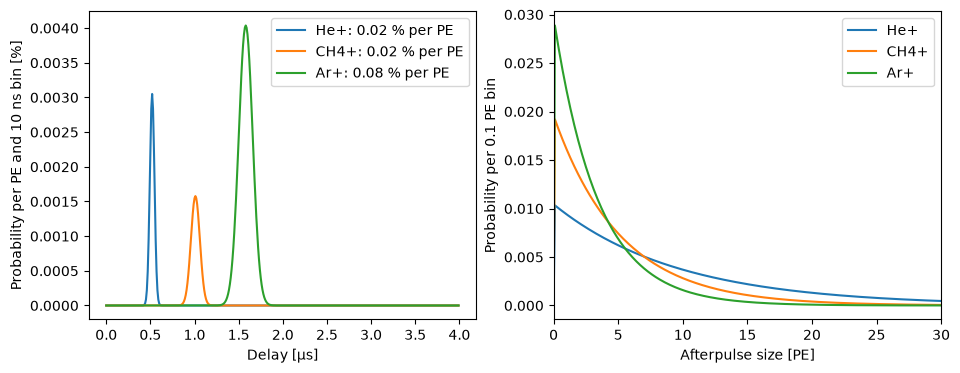

In [4]:
afterpulse_config = strax.URLConfig.evaluate_dry("ember_file://pmt_afterpulse_config_dummy.json.gz")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ion, entry in afterpulse_config.items():
    delay_cdf = np.array(entry["delaytime_cdf"][0])
    delays = np.arange(len(delay_cdf)) * entry["delaytime_bin_size"]
    axes[0].plot(delays / 1000, np.diff(delay_cdf, prepend=0) * 100, label=f"{ion}: {100 * delay_cdf[-1]:.2f} % per PE")
    size_cdf = np.array(entry["amplitude_cdf"])
    sizes = np.arange(len(size_cdf)) * entry["amplitude_bin_size"]
    axes[1].plot(sizes, np.diff(size_cdf, prepend=0), label=ion)
axes[0].set_xlabel("Delay [µs]")
axes[0].set_ylabel("Probability per PE and 10 ns bin [%]")
axes[0].legend()
axes[1].set_xlabel("Afterpulse size [PE]")
axes[1].set_ylabel("Probability per 0.1 PE bin")
axes[1].set_xlim(0, 30)
axes[1].legend()
plt.show()

In total 0.12 % of the photoelectrons create an afterpulse. Let us check this with the simulation:

In [5]:
afterpulses = st.get_array(run_id, "pmt_afterpulses")

all_photons_n = len(s1_photons) + len(s2_photons)
double_pe_n = s1_photons["dpe"].sum() + s2_photons["dpe"].sum()
expected = 0.0012 * (all_photons_n + double_pe_n)
print("Afterpulses:", len(afterpulses))
print(f"Expected:    {expected:.0f} ± {np.sqrt(expected):.0f}")

Loading pmt_afterpulses: |          | 0.00 % [00:00<?]

Afterpulses: 27461
Expected:    27596 ± 166


The afterpulses are not linked to their photon, so we look at the delays with the function the plugin uses: 100 000 photons at t = 0 in channel 0.

Afterpulses (probability scaled up by 10): 1209


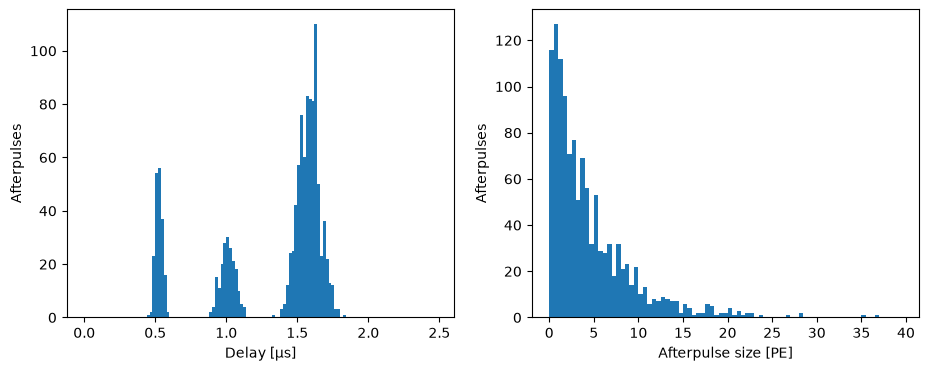

In [6]:
from ember.plugins.pmt_and_daq.pmt_afterpulses import draw_afterpulses, read_afterpulse_elements

plugin = st.get_single_plugin(run_id, "pmt_afterpulses")
n_test_photons = 100_000
times, channels, gains = draw_afterpulses(
    photon_times=np.zeros(n_test_photons, dtype=np.int64),
    photon_channels=np.zeros(n_test_photons, dtype=np.int16),
    photon_is_dpe=np.zeros(n_test_photons, dtype=bool),
    afterpulse_elements=plugin.afterpulse_elements,
    gains=plugin.gains,
    afterpulse_modifier=10.0,
    afterpulse_time_modifier=0.0,
    rng=np.random.default_rng(1),
)
print("Afterpulses (probability scaled up by 10):", len(times))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(times / 1000, bins=np.arange(0, 2.5, 0.02))
axes[0].set_xlabel("Delay [µs]")
axes[0].set_ylabel("Afterpulses")
axes[1].hist(gains / plugin.gains[0], bins=np.arange(0, 40, 0.5))
axes[1].set_xlabel("Afterpulse size [PE]")
axes[1].set_ylabel("Afterpulses")
plt.show()

### Settings

| Option | Default | Meaning |
|---|---|---|
| `enable_pmt_afterpulses` | `detector://enable_pmt_afterpulses` (true) | switch afterpulses on or off |
| `pmt_ap_modifier` | 1.0 | scales all afterpulse probabilities |
| `pmt_ap_t_modifier` | 0 ns | subtracted from all delays |
| `photon_ap_cdfs` | `ember_file://pmt_afterpulse_config_dummy.json.gz` | afterpulse file (fuse's format) |

Unlike fuse, ember draws delay and size with the inverse of the cumulative distribution. fuse takes the bin whose cumulative value is closest to the random number, which gives delays half a bin (5 ns) too early on average and sometimes afterpulses of 0 PE.

## 3. `PhotonSummary`: all photons in one list

`PhotonSummary` concatenates the S1, S2 and afterpulse photons and sorts them by time:

In [7]:
photon_summary = st.get_array(run_id, "photon_summary")

for photon_type, name in [(1, "S1"), (2, "S2"), (0, "afterpulse")]:
    print(f"{name:11s} photons: {np.sum(photon_summary['photon_type'] == photon_type):10d}")
print("Sorted by time:", np.all(np.diff(photon_summary["time"]) >= 0))

Loading photon_summary: |          | 0.00 % [00:00<?]

S1          photons:     265632
S2          photons:   18598440
afterpulse  photons:      27461
Sorted by time: True


## 4. `PulseWindow`: which photons end up in the same waveform?

The pulses of photons that arrive close in time in the same PMT overlap and form one waveform. `PulseWindow` gives every photon a window from `2 · samples_to_store_before + samples_before_pulse_center` samples before to `2 · samples_to_store_after + samples_after_pulse_center` samples after the photon (here −1020 ns to +1400 ns). Overlapping windows of one channel are merged. Every photon gets the `pulse_id` of its window (`pulse_ids`, one row per photon).

An S2 lasts a few µs, so its photons in one PMT usually form one long window, while a single S1 photon gets its own short window:

Loading pulse_windows: |          | 0.00 % [00:00<?]

Loading pulse_ids: |          | 0.00 % [00:00<?]

Pulse windows: 705005


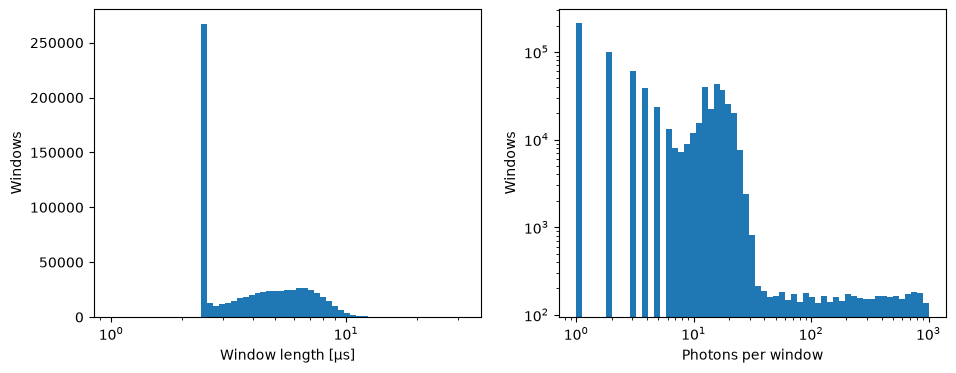

In [8]:
pulse_windows = st.get_array(run_id, "pulse_windows")
pulse_ids = st.get_array(run_id, "pulse_ids")
photons_per_window = np.bincount(pulse_ids["pulse_id"] - pulse_ids["pulse_id"].min())
photons_per_window = photons_per_window[photons_per_window > 0]

print("Pulse windows:", len(pulse_windows))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(pulse_windows["length"] * sample_duration / 1000, bins=np.logspace(0, 1.5, 60))
axes[0].set_xscale("log")
axes[0].set_xlabel("Window length [µs]")
axes[0].set_ylabel("Windows")
axes[1].hist(photons_per_window, bins=np.logspace(0, 3, 60))
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("Photons per window")
axes[1].set_ylabel("Windows")
plt.show()

## 5. `PMTResponseAndDAQ`: from photons to ADC samples

For every pulse window the plugin builds the waveform in five steps:

1. **PMT pulses.** Every photon adds one single photoelectron (SPE) pulse, scaled with its gain. The pulse shape comes from `pmt_pulse_shape_dummy.json` (made in `map_generators/dummy_pmt_pulse.ipynb`): a log-normal pulse with the rise time, fall time and width measured for the Hamamatsu R11410-10, smeared with a normal distribution (σ = `pmt_pulse_smearing_sigma`, 3 ns) to account for the widening by cables, amplifier and digitizer. The plugin integrates it over the 10 ns samples, separately for every ns at which a photon can arrive within a sample (*templates*).
2. **ADC conversion.** The current is converted to ADC counts with the load resistor, the amplifier and the digitizer range, and rounded. A pulse of 1 PE has an area of `1 / pmt_to_pe` = 200 ADC counts × samples.
3. **Noise.** Noise from the noise file (`noise_dummy.npz`, white Gaussian noise, σ = `noise_sigma` from `detector.yaml`) is added.
4. **Baseline.** PMT pulses are negative, so the waveform is `baseline − signal`.
5. **Zero-length encoding (ZLE).** Like the DAQ, only the parts of the waveform where the signal goes below `baseline − zle_threshold` are stored, plus `trigger_window` samples before and after. These parts are split into records of 110 samples.

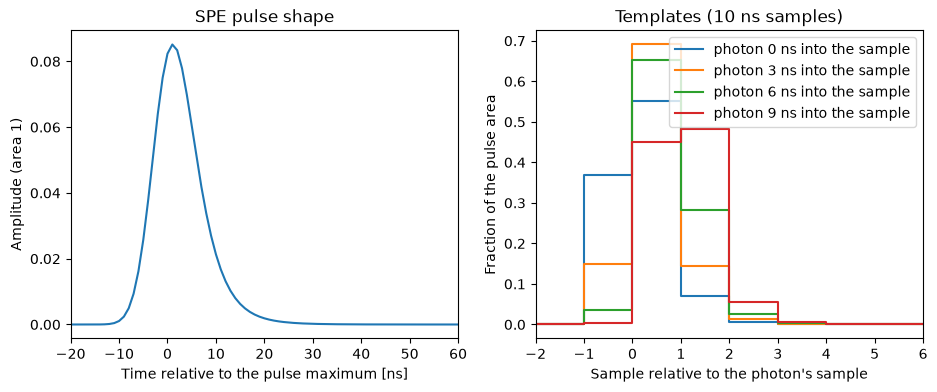

In [9]:
pulse_shape = strax.URLConfig.evaluate_dry("ember_file://pmt_pulse_shape_dummy.json")
daq_plugin = st.get_single_plugin(run_id, "raw_records")
templates = daq_plugin.pmt_current_templates
template_samples = np.arange(templates.shape[1]) - daq_plugin.samples_before_pulse_center

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(pulse_shape["pe_pulse_ts"], pulse_shape["pe_pulse_ys"])
axes[0].set_xlim(-20, 60)
axes[0].set_xlabel("Time relative to the pulse maximum [ns]")
axes[0].set_ylabel("Amplitude (area 1)")
axes[0].set_title("SPE pulse shape")
for offset in [0, 3, 6, 9]:
    axes[1].step(template_samples, templates[offset] * sample_duration, where="post", label=f"photon {offset} ns into the sample")
axes[1].set_xlim(-2, 6)
axes[1].set_xlabel("Sample relative to the photon's sample")
axes[1].set_ylabel("Fraction of the pulse area")
axes[1].set_title("Templates (10 ns samples)")
axes[1].legend()
plt.show()

The template sample 0 is placed at the photon's sample. Since the templates start `samples_before_pulse_center` = 2 samples before the pulse maximum, the maximum of a pulse ends up about 20 ns after the photon time. This constant shift is inherited from fuse.

Now the `raw_records`. We first look at one waveform of the first S2: the PMT with the most photons of this S2.

Making the `raw_records` of all 1000 betas takes about half a minute. A time range can only be selected from stored data, so we make them first:

In [10]:
st.make(run_id, "raw_records", progress_bar=True)

Removing old incomplete data in strax_data/000001-raw_records-zgtvf5sqtg_temp


Loading raw_records: |          | 0.00 % [00:00<?]

INFO:PMTResponseAndDAQ:Chunk size exceeding file size target. Downchunking to 2 chunks
INFO:PMTResponseAndDAQ:Chunk size exceeding file size target. Downchunking to 2 chunks


The raw waveforms become quite large, the data size can be checked with:

In [11]:
st.size_mb(run_id, "raw_records")

501.06254

Loading raw_records: |          | 0.00 % [00:00<?]

Channel 223: 5113 photons, 6 records


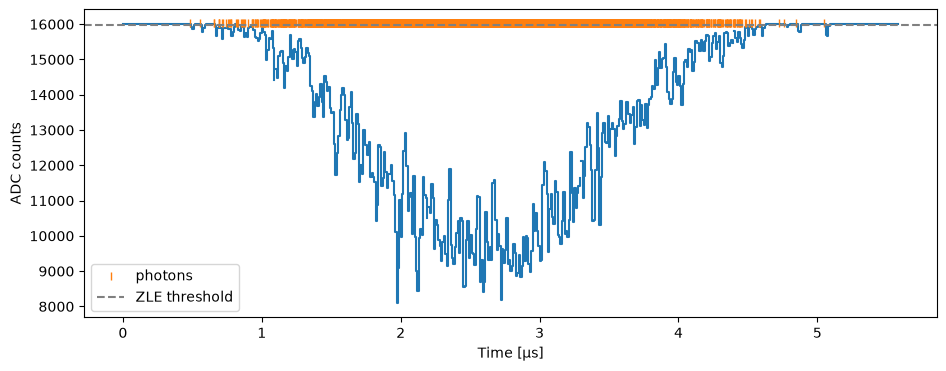

In [12]:
first_interaction = microphysics_summary[0]
s2_of_first = s2_photons[s2_photons["cluster_id"] == first_interaction["cluster_id"]]
channel = np.bincount(s2_of_first["channel"]).argmax()
photons_in_channel = photon_summary[
    (photon_summary["channel"] == channel)
    & (photon_summary["time"] >= s2_of_first["time"].min() - 5000)
    & (photon_summary["time"] <= s2_of_first["time"].max() + 5000)
]

# Get raw records of this S2 signal:
time_range = (int(photons_in_channel["time"].min()) - 5000, int(photons_in_channel["time"].max()) + 5000)
records = st.get_array(run_id, "raw_records", time_range=time_range, selection=f"channel == {channel}")
print(f"Channel {channel}: {len(photons_in_channel)} photons, {len(records)} records")

start = records["time"].min()
fig, ax = plt.subplots(figsize=(11, 4))
for record in records:
    sample_times = (record["time"] - start + np.arange(record["length"]) * sample_duration) / 1000
    ax.step(sample_times, record["data"][: record["length"]], where="post", color="C0")
ax.plot((photons_in_channel["time"] - start) / 1000, np.full(len(photons_in_channel), baseline + 20), "|", color="C1", label="photons")
ax.axhline(baseline - zle_threshold, color="gray", linestyle="--", label="ZLE threshold")
ax.set_xlabel("Time [µs]")
ax.set_ylabel("ADC counts")
ax.legend()
plt.show()

Zoom into the start of the waveform: the signal starts with `trigger_window` samples of baseline (with noise), which abstrax uses to determine the baseline.

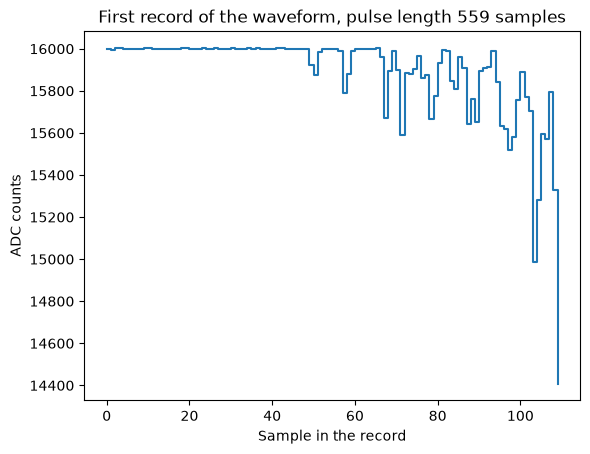

In [13]:
first_record = records[records["record_i"] == 0][0]
plt.step(np.arange(first_record["length"]), first_record["data"][: first_record["length"]], where="post")
plt.xlabel("Sample in the record")
plt.ylabel("ADC counts")
plt.title(f"First record of the waveform, pulse length {first_record['pulse_length']} samples")
plt.show()

This PMT signals are quite narrow compared to true signals. However,  ember is only meant as a starting point for your own detector development so for the documentation and illustration of the working principle of this package it is sufficient.

### The `raw_records` format

| Field | Meaning |
|---|---|
| `time` | start of the record [ns] |
| `length` | number of valid samples in this record (≤ 110) |
| `dt` | sample duration [ns] |
| `channel` | PMT |
| `pulse_length` | number of samples of the whole stored waveform part |
| `record_i` | number of the record within this waveform part |
| `data` | ADC samples, padded with 0 after `length` |

This is strax's standard format, the same as for measured data.

In [14]:
print("raw_records:", st.size_mb(run_id, "raw_records"), "MB in memeory")
print("photon_summary:", st.size_mb(run_id, "photon_summary"), "MB in memory")

raw_records: 501.06254 MB in memeory
photon_summary: 528.962924 MB in memory


### Settings

In [15]:
st.show_config("raw_records")

,option,default,current,applies_to,help
0,debug,False,<OMITTED>,"(raw_records,)",Show debug informations
1,deterministic_seed,True,<OMITTED>,"(raw_records,)","Set the random seed from lineage and run_id, o..."
2,user_defined_random_seed,None,<OMITTED>,"(raw_records,)",Define the random seed manually. You need to s...
3,dt,detector://sample_duration,<OMITTED>,"(raw_records,)",Width of one sample [ns]
4,pmt_circuit_load_resistor,detector://pmt_circuit_load_resistor,<OMITTED>,"(raw_records,)",Conversion constant from PMT current to voltag...
...,...,...,...,...,...
148,user_defined_random_seed,None,<OMITTED>,"(s1_photon_hits,)",Define the random seed manually. You need to s...
149,gain_model_mc,ember_pmt_to_pe://,<OMITTED>,"(s1_photon_hits,)",ADC-to-PE factor per channel; channels with 0 ...
150,s1_pattern_map,ember_map://s1_pattern_map_dummy.pkl?method=li...,<OMITTED>,"(s1_photon_hits,)",S1 light collection efficiency per channel [PE...
151,p_double_pe_emission,detector://p_double_pe_emission,<OMITTED>,"(s1_photon_hits,)",Probability of double photo-electron emission


| Option | Default | Meaning |
|---|---|---|
| `pe_pulse_shape` | `ember_file://pmt_pulse_shape_dummy.json` | SPE pulse shape (fuse's keys `pe_pulse_ts`, `pe_pulse_ys`) |
| `noise_data` | `ember_file://noise_dummy.npz` | noise per channel (`arr_0`, samples × channels) |
| `enable_noise` | true | switch noise on or off |
| `zle_threshold`, `trigger_window`, `special_thresholds` | 15 ADC, 50 samples, {} | zero-length encoding |
| `digitizer_reference_baseline`, `digitizer_bits`, `digitizer_voltage_range`, `external_amplification` | 16000, 14, 2.25 V, 10 | digitizer |
| `raw_records_file_size_target`, `min_records_gap_length_for_splitting` | 200 MB, 100 µs | output chunk size (not part of the lineage) |

**Note on the PE scale:** the area of a 1 PE pulse is `external_amplification / sample_duration / pmt_to_pe` ADC counts × samples. With 10 / 10 ns the first factor is 1. If you change `external_amplification` or `sample_duration`, change `pmt_to_pe` in `detector.yaml` accordingly.

Changing an option changes the lineage, so strax simulates the `raw_records` again (about half a minute and 1 GB for these 1000 betas). For example, `st.set_config({"enable_noise": False})` gives waveforms without noise, and `st.set_config({"enable_pmt_afterpulses": False})` switches the afterpulses off.

## 6. Processing the simulated data with abstrax

ember stops at `raw_records`. From here, abstrax processes the data like measured data: `raw_records` → `records` → `peaks` → `events`.

This section needs the optional package abstrax (`pip install "ember[abstrax]"`); ember itself runs without it.

ember and abstrax read their detector settings with the same URLs, `detector://key`, so the lineages are the same in both packages. When ember is imported, `detector://` reads `ember/config/detector.yaml` (whether abstrax was imported before or after ember), which contains all settings of abstrax's detector file with the same names and values (marked `[shared]`). Both packages therefore describe the same detector, and abstrax's plugins can simply be registered in the ember context. abstrax's `DAQReader` is not needed: ember provides the `raw_records`.

abstrax's peak finding needs the PMT gains (`gain_model`, PE per ADC count). We use the same gains as the simulation, including switched-off channels:

In [18]:
from abstrax.contexts import ABSTRAX_PLUGINS

ModuleNotFoundError: No module named 'abstrax'

In [26]:
try:
    from abstrax.contexts import ABSTRAX_PLUGINS
    st.register(ABSTRAX_PLUGINS)
    st.set_config({"gain_model": "ember_pmt_to_pe://"})

    print("detector:// reads", strax.URLConfig.evaluate_dry("detector://n_tpc_pmts"), "channels from the ember file")

except ModuleNotFoundError as e:
    raise ModuleNotFoundError(
    'Please install AxFoundation/abstrax from github to proceed with this part of the tutorial.'
    )



ModuleNotFoundError: Please install AxFoundation/abstrax from github to proceed with this part of the tutorial.

abstrax's `PulseProcessing` subtracts the baseline (estimated on the first 40 samples of each waveform part), finds hits and integrates the records. The total area is the same as in the simulated photons (the DAQ simulation conserves the area). These ZLE encoded waveforms are than used to build peaks for which basic properties are computed in `PeakBasics`. If you want to learn more about `abstrax` and its processing strcuture please refer to the package.

In [22]:
peaks = st.get_array(run_id, "peak_basics")

spe_gain = st.get_single_plugin(run_id, "pmt_afterpulses").gains[0]
print(f"Photons:      {photon_summary['photon_gain'].sum() / spe_gain:12.0f} PE")
print(f"abstrax peaks: {peaks['area'].sum():12.0f} PE")
for peak_type, name in [(1, "S1"), (2, "S2"), (0, "unclassified")]:
    print(f"{name:12s} peaks: {np.sum(peaks['type'] == peak_type)}")

Loading peak_basics: |          | 0.00 % [00:00<?]

/mnt/d/XLZD/mymodules/strax/strax/processing/general.py:397: UserWarning: endtime of things is not sorted! touching_windows will return the indices of the first and last things which are touching the container.
  warnings.warn(
/mnt/d/XLZD/mymodules/strax/strax/processing/general.py:397: UserWarning: endtime of things is not sorted! touching_windows will return the indices of the first and last things which are touching the container.
  warnings.warn(
/mnt/d/XLZD/mymodules/strax/strax/processing/general.py:397: UserWarning: endtime of things is not sorted! touching_windows will return the indices of the first and last things which are touching the container.
  warnings.warn(
/mnt/d/XLZD/mymodules/strax/strax/processing/general.py:397: UserWarning: endtime of things is not sorted! touching_windows will return the indices of the first and last things which are touching the container.
  warnings.warn(
/mnt/d/XLZD/mymodules/strax/strax/processing/general.py:397: UserWarning: endtime of thi

Photons:          15505572 PE
abstrax peaks:     15498237 PE
S1           peaks: 1014
S2           peaks: 1351
unclassified peaks: 31


We can also plot the S2 waveform of our earlier example again:

In [28]:
some_s2_peaks = st.get_array(run_id, 'peaks', selection='type==2', seconds_range=(0, 1))
first_s2 = some_s2_peaks[0]

Loading peaks: |          | 0.00 % [00:00<?]

Text(0, 0.5, 'Amplitude [PE/sample]')

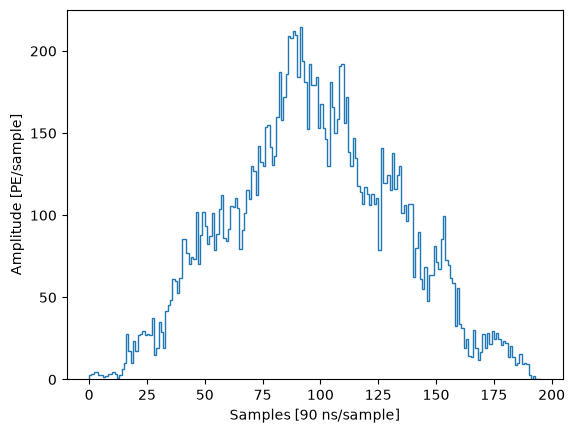

In [31]:
plt.stairs(
    first_s2['data'][:first_s2['length']],
    np.arange(first_s2['length']+1),
)
plt.xlabel(f'Samples [{first_s2["dt"]} ns/sample]')
plt.ylabel('Amplitude [PE/sample]')

Each S2 is downsampled such that it fits into a 200 sample buffer.

Finally the events. Each beta gives one event with an S1 and an S2:

Loading event_info: |          | 0.00 % [00:00<?]

Events: 998 of 1000 interactions


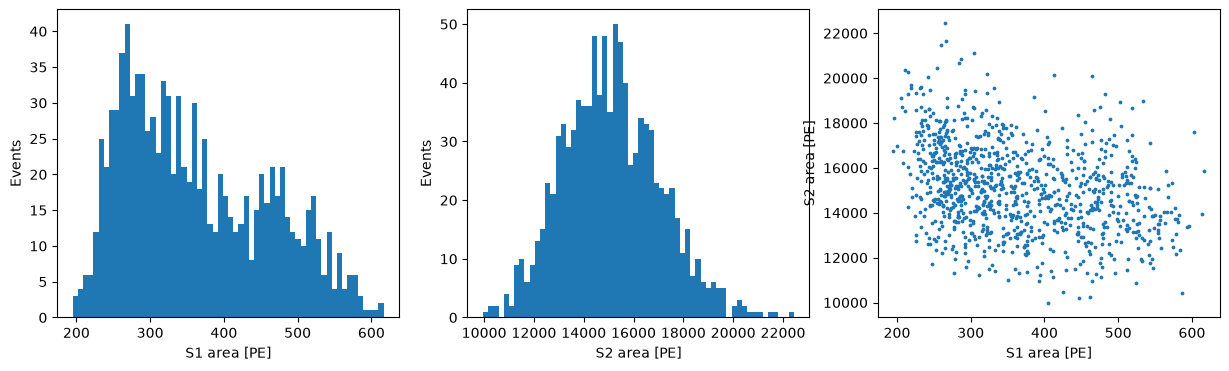

In [32]:
event_info = st.get_df(run_id, "event_info")
print("Events:", len(event_info), "of", len(microphysics_summary), "interactions")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(event_info["s1_area"], bins=60)
axes[0].set_xlabel("S1 area [PE]")
axes[0].set_ylabel("Events")
axes[1].hist(event_info["s2_area"], bins=60)
axes[1].set_xlabel("S2 area [PE]")
axes[1].set_ylabel("Events")
axes[2].scatter(event_info["s1_area"], event_info["s2_area"], s=3)
axes[2].set_xlabel("S1 area [PE]")
axes[2].set_ylabel("S2 area [PE]")
plt.show()

(0.0, 2500.0)

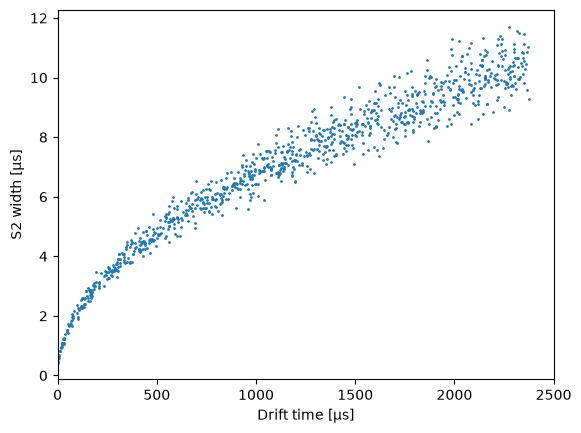

In [37]:
plt.scatter(
    event_info['drift_time']/1000,
    event_info['s2_range_50p_area']/1000,
    s=1
)
plt.xlabel('Drift time [µs]')
plt.ylabel('S2 width [µs]')
plt.xlim(0, 2500)

The mean S1 and S2 areas follow from the detector parameters of the simulation: $\langle S1 \rangle \approx g_1 \langle N_\gamma \rangle$ and $\langle S2 \rangle \approx g_2 \langle N_e \rangle$ reduced by the electron losses during the drift (electron lifetime, tutorial 3):

In [33]:
g1 = detector_value("g1")
g2 = detector_value("g2")
print(f"Mean S1 area: {event_info['s1_area'].mean():8.1f} PE   g1 · <photons>   = {g1 * microphysics_summary['photons'].mean():8.1f} PE")
print(f"Mean S2 area: {event_info['s2_area'].mean():8.1f} PE   g2 · <electrons> = {g2 * microphysics_summary['electrons'].mean():8.1f} PE")

Mean S1 area:    362.3 PE   g1 · <photons>   =    360.5 PE
Mean S2 area:  15121.1 PE   g2 · <electrons> =  15930.5 PE


## Summary

- `PMTAfterPulses` adds afterpulses as photons with `photon_type = 0` (dummy: He⁺, CH₄⁺, Ar⁺, 0.12 % per PE).
- `PhotonSummary` merges all photons, `PulseWindow` groups the photons of one PMT into windows.
- `PMTResponseAndDAQ` builds the waveforms (SPE pulse shape, ADC conversion, noise, baseline) and stores the parts above the ZLE threshold as `raw_records`.
- The dummy inputs (pulse shape, noise, afterpulses) are made in `map_generators/`; replace them with measurements of your PMTs and DAQ.
- ember and abstrax share the detector settings (`detector://`), so abstrax's plugins can be registered in the ember context and process the simulated `raw_records` like measured data.